In [29]:
import joblib
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
df = pd.read_csv('../tas2_yontem1.csv')

pipeline = joblib.load('kmeans_3segment.pkl')
yontem1df = df.copy()
yontem1df['max_price'] = df['max_price'].fillna(df['max_price'].median())
yontem1df['min_price'] = df['min_price'].fillna(df['min_price'].median())
yontem1df['gender'] = df['gender'].fillna("NULL")
yontem1df['message'] = df['message'].fillna("NULL")
yontem1df['comment'] = df['comment'].fillna("NULL")
yontem1df['deviceType'] = df['deviceType'].fillna("NULL")
yontem1df['categories'] = df['categories'].fillna("NULL")
yontem1df['contents'] = df['contents'].fillna("NULL")
df = yontem1df.copy()
predictions = pipeline.predict(df)
df['segment'] = predictions
df
df['segment'].value_counts()


segment
1    49
0    36
2    22
Name: count, dtype: int64

In [30]:
numerical_features = df.select_dtypes(include=['float64', 'int64']).columns

categorical_features = df.select_dtypes(include=['object']).columns
segment_summary_numeric = df.groupby('segment')[numerical_features].mean().round(2)

print("📊 Segment Bazlı Sayısal Özellik Ortalamaları:\n")
segment_summary_numeric

📊 Segment Bazlı Sayısal Özellik Ortalamaları:



,pageDuration,clicks,focusLossCount,sessionDuration,min_price,max_price
segment,,,,,,
0,2506683.83,14.47,56.00,31470828.36,34858.94,500.0
1,317881.80,40.14,25.39,13387463.49,639.52,500.0
2,1783455.23,83.00,133.00,36422086.00,661.50,500.0


📉 Segment Bazlı Sayısal Özellik Dağılımları:


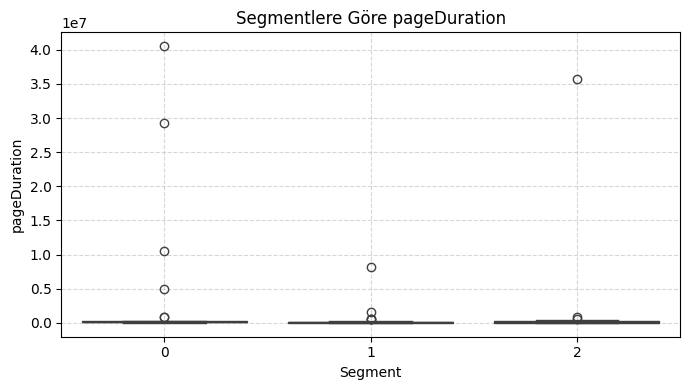

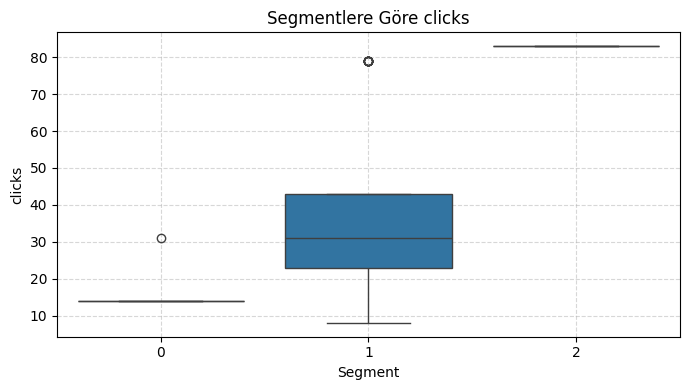

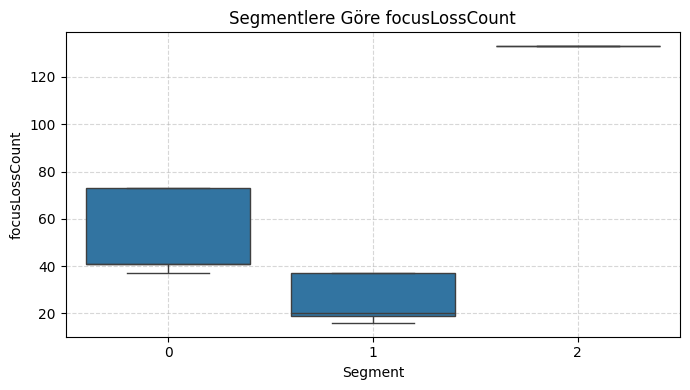

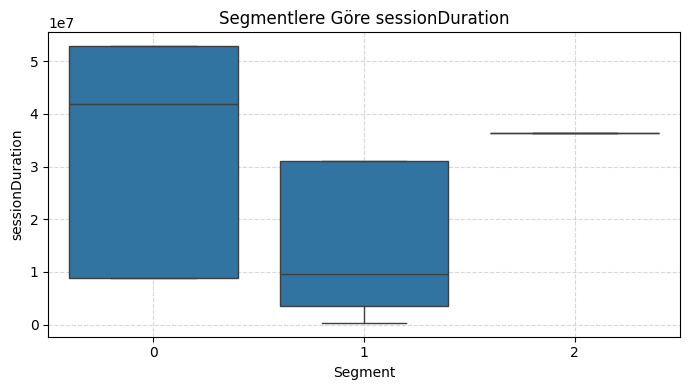

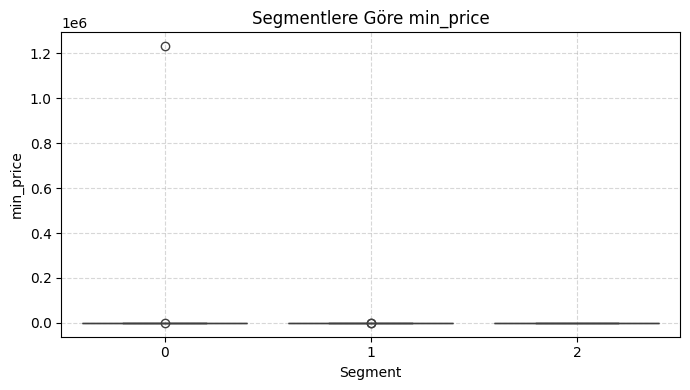

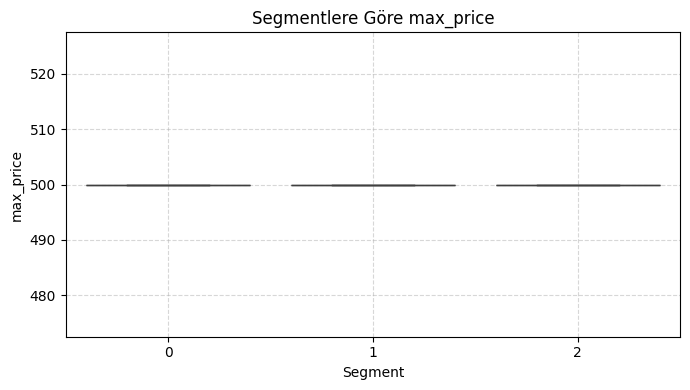

In [31]:
import seaborn as sns
import matplotlib.pyplot as plt

print("📉 Segment Bazlı Sayısal Özellik Dağılımları:")

for col in numerical_features:
    plt.figure(figsize=(7, 4))
    sns.boxplot(data=df, x='segment', y=col)
    plt.title(f'Segmentlere Göre {col}')
    plt.xlabel('Segment')
    plt.ylabel(col)
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.show()


In [47]:
# Başlangıç: segmentleri sıralı şekilde indeks yap
crosstab_df = pd.DataFrame(index=sorted(df['segment'].unique()))

cols = ["deviceType", "gender"]
# Her kategorik özelliği işle
for col in cols:
    ct = pd.crosstab(df['segment'], df[col], normalize='index')
    ct.columns = [f"{col}_{val}" for val in ct.columns]
    crosstab_df = crosstab_df.join(ct, how='outer')

# Oranları % olarak göster (opsiyonel)
crosstab_df = (crosstab_df * 100).round(2)
crosstab_df = crosstab_df.reset_index().rename(columns={'index': 'segment'})

crosstab_df

,segment,deviceType_NULL,deviceType_desktop,deviceType_mobile,deviceType_tablet,gender_NULL,gender_male
0,0,2.78,97.22,0.0,0.00,100.00,0.00
1,1,30.61,28.57,0.0,40.82,95.92,4.08
2,2,0.00,0.00,100.0,0.00,100.00,0.00


In [45]:
numerical_features = df.select_dtypes(include=['float64', 'int64']).columns


segment_summary_numeric = df.groupby('segment')[numerical_features].mean().round(2)
segment_summary_numeric = segment_summary_numeric.reset_index()
segment_summary_numeric

,segment,pageDuration,clicks,focusLossCount,sessionDuration,min_price,max_price
0,0,2506683.83,14.47,56.00,31470828.36,34858.94,500.0
1,1,317881.80,40.14,25.39,13387463.49,639.52,500.0
2,2,1783455.23,83.00,133.00,36422086.00,661.50,500.0


In [49]:
merged_df = pd.merge(segment_summary_numeric, crosstab_df, on='segment')
merged_df

,segment,pageDuration,clicks,focusLossCount,sessionDuration,min_price,max_price,deviceType_NULL,deviceType_desktop,deviceType_mobile,deviceType_tablet,gender_NULL,gender_male
0,0,2506683.83,14.47,56.00,31470828.36,34858.94,500.0,2.78,97.22,0.0,0.00,100.00,0.00
1,1,317881.80,40.14,25.39,13387463.49,639.52,500.0,30.61,28.57,0.0,40.82,95.92,4.08
2,2,1783455.23,83.00,133.00,36422086.00,661.50,500.0,0.00,0.00,100.0,0.00,100.00,0.00


In [50]:
segment_json = merged_df.to_dict(orient='records')
import json
print(json.dumps(segment_json, indent=2))

[
  {
    "segment": 0,
    "pageDuration": 2506683.83,
    "clicks": 14.47,
    "focusLossCount": 56.0,
    "sessionDuration": 31470828.36,
    "min_price": 34858.94,
    "max_price": 500.0,
    "deviceType_NULL": 2.78,
    "deviceType_desktop": 97.22,
    "deviceType_mobile": 0.0,
    "deviceType_tablet": 0.0,
    "gender_NULL": 100.0,
    "gender_male": 0.0
  },
  {
    "segment": 1,
    "pageDuration": 317881.8,
    "clicks": 40.14,
    "focusLossCount": 25.39,
    "sessionDuration": 13387463.49,
    "min_price": 639.52,
    "max_price": 500.0,
    "deviceType_NULL": 30.61,
    "deviceType_desktop": 28.57,
    "deviceType_mobile": 0.0,
    "deviceType_tablet": 40.82,
    "gender_NULL": 95.92,
    "gender_male": 4.08
  },
  {
    "segment": 2,
    "pageDuration": 1783455.23,
    "clicks": 83.0,
    "focusLossCount": 133.0,
    "sessionDuration": 36422086.0,
    "min_price": 661.5,
    "max_price": 500.0,
    "deviceType_NULL": 0.0,
    "deviceType_desktop": 0.0,
    "deviceType_mobi